In [1]:
import sys
import torch
from pathlib import Path
import PIL
import matplotlib
import numpy as np

print(f"Python version : {sys.version.split()[0]}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device = torch.device("cuda:0")
    print(f"Device Name    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    device = torch.device("cpu")
    print("WARNING: CUDA not available. Running on CPU.")
    

Python version : 3.10.20
PyTorch version: 2.6.0+cu124
CUDA Available : True
Device Name    : NVIDIA GeForce RTX 3050 Laptop GPU
VRAM Available : 3.68 GB


In [2]:
# 1. Dynamically resolve project root
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "data").exists() else cwd.parent
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "toothbrush"

assert DATA_DIR.exists(), f"ERROR: Toothbrush directory not found at {DATA_DIR}"

# 2. Collect and sort all image paths
train_good_paths = sorted(list((DATA_DIR / "train" / "good").glob("*.png")))
test_good_paths = sorted(list((DATA_DIR / "test" / "good").glob("*.png")))
test_defective_paths = sorted(list((DATA_DIR / "test" / "defective").glob("*.png")))
ground_truth_paths = sorted(list((DATA_DIR / "ground_truth" / "defective").glob("*.png")))

print(f"Project Root          : {PROJECT_ROOT}")
print(f"Dataset Location      : {DATA_DIR}")
print("-" * 55)
print(f"Normal Train Images   : {len(train_good_paths)}")
print(f"Normal Test Images    : {len(test_good_paths)}")
print(f"Defective Test Images : {len(test_defective_paths)}")
print(f"Ground Truth Masks    : {len(ground_truth_paths)}")

# 3. Sanity check: verify that every defective test image has a matching mask
defective_stems = {p.stem for p in test_defective_paths}
mask_stems = {p.stem.replace("_mask", "") for p in ground_truth_paths}

unmatched = defective_stems.symmetric_difference(mask_stems)
print("-" * 55)
if len(unmatched) == 0:
    print("Verification Passed: 100% 1-to-1 match between defective images and masks!")
else:
    print(f"WARNING: Unmatched image/mask IDs found: {unmatched}")

Project Root          : /home/asus/Defect  Detection
Dataset Location      : /home/asus/Defect  Detection/data/raw/toothbrush
-------------------------------------------------------
Normal Train Images   : 60
Normal Test Images    : 12
Defective Test Images : 30
Ground Truth Masks    : 30
-------------------------------------------------------
Verification Passed: 100% 1-to-1 match between defective images and masks!


In [3]:
from PIL import Image

# 1. Audit dimensions and color modes across all 102 product images
all_image_paths = train_good_paths + test_good_paths + test_defective_paths

image_shapes = set()
image_modes = set()

for p in all_image_paths:
    with Image.open(p) as img:
        image_shapes.add(img.size)  # PIL returns (width, height)
        image_modes.add(img.mode)

# 2. Audit ground-truth masks for resolution and binary pixel values
mask_shapes = set()
mask_modes = set()
mask_unique_values = set()

for p in ground_truth_paths:
    with Image.open(p) as m:
        mask_shapes.add(m.size)
        mask_modes.add(m.mode)
        mask_arr = np.array(m)
        mask_unique_values.update(np.unique(mask_arr))

print("=== Image Audit Results ===")
print(f"Total Images Inspected : {len(all_image_paths)}")
print(f"Unique Image Sizes     : {image_shapes} (width, height)")
print(f"Unique Color Modes     : {image_modes}")
print("-" * 50)
print("=== Mask Audit Results ===")
print(f"Total Masks Inspected  : {len(ground_truth_paths)}")
print(f"Unique Mask Sizes      : {mask_shapes} (width, height)")
print(f"Unique Mask Modes      : {mask_modes}")
print(f"Unique Mask Pixel Vals : {sorted(list(mask_unique_values))}")

=== Image Audit Results ===
Total Images Inspected : 102
Unique Image Sizes     : {(1024, 1024)} (width, height)
Unique Color Modes     : {'RGB'}
--------------------------------------------------
=== Mask Audit Results ===
Total Masks Inspected  : 30
Unique Mask Sizes      : {(1024, 1024)} (width, height)
Unique Mask Modes      : {'L'}
Unique Mask Pixel Vals : [np.uint8(0), np.uint8(255)]


In [4]:
import pandas as pd

# Calculate defect area for every ground-truth mask
defect_stats = []

for p in ground_truth_paths:
    with Image.open(p) as m:
        mask_arr = np.array(m)
        total_pixels = mask_arr.size  # 1024 * 1024 = 1,048,576
        defect_pixels = int(np.sum(mask_arr == 255))
        defect_pct = (defect_pixels / total_pixels) * 100.0
        
        defect_stats.append({
            "image_id": p.stem.replace("_mask", ""),
            "defect_pixels": defect_pixels,
            "defect_area_pct": defect_pct
        })

df_defects = pd.DataFrame(defect_stats)

print("=== Toothbrush Defect Size Distribution ===")
print(f"Total Defective Samples : {len(df_defects)}")
print(f"Minimum Defect Area     : {df_defects['defect_area_pct'].min():.4f}% ({df_defects['defect_pixels'].min():,} px)")
print(f"Median Defect Area      : {df_defects['defect_area_pct'].median():.4f}% ({int(df_defects['defect_pixels'].median()):,} px)")
print(f"Mean Defect Area        : {df_defects['defect_area_pct'].mean():.4f}% ({int(df_defects['defect_pixels'].mean()):,} px)")
print(f"Maximum Defect Area     : {df_defects['defect_area_pct'].max():.4f}% ({df_defects['defect_pixels'].max():,} px)")
print("-" * 50)
print("\nTop 5 Smallest Defects:")
display(df_defects.sort_values(by="defect_pixels").head(5))

=== Toothbrush Defect Size Distribution ===
Total Defective Samples : 30
Minimum Defect Area     : 0.2381% (2,497 px)
Median Defect Area      : 1.0778% (11,302 px)
Mean Defect Area        : 2.1410% (22,449 px)
Maximum Defect Area     : 12.9764% (136,067 px)
--------------------------------------------------

Top 5 Smallest Defects:


,image_id,defect_pixels,defect_area_pct
7,007,2497,0.238132
4,004,2630,0.250816
21,021,2649,0.252628
27,027,2911,0.277615
18,018,3148,0.300217


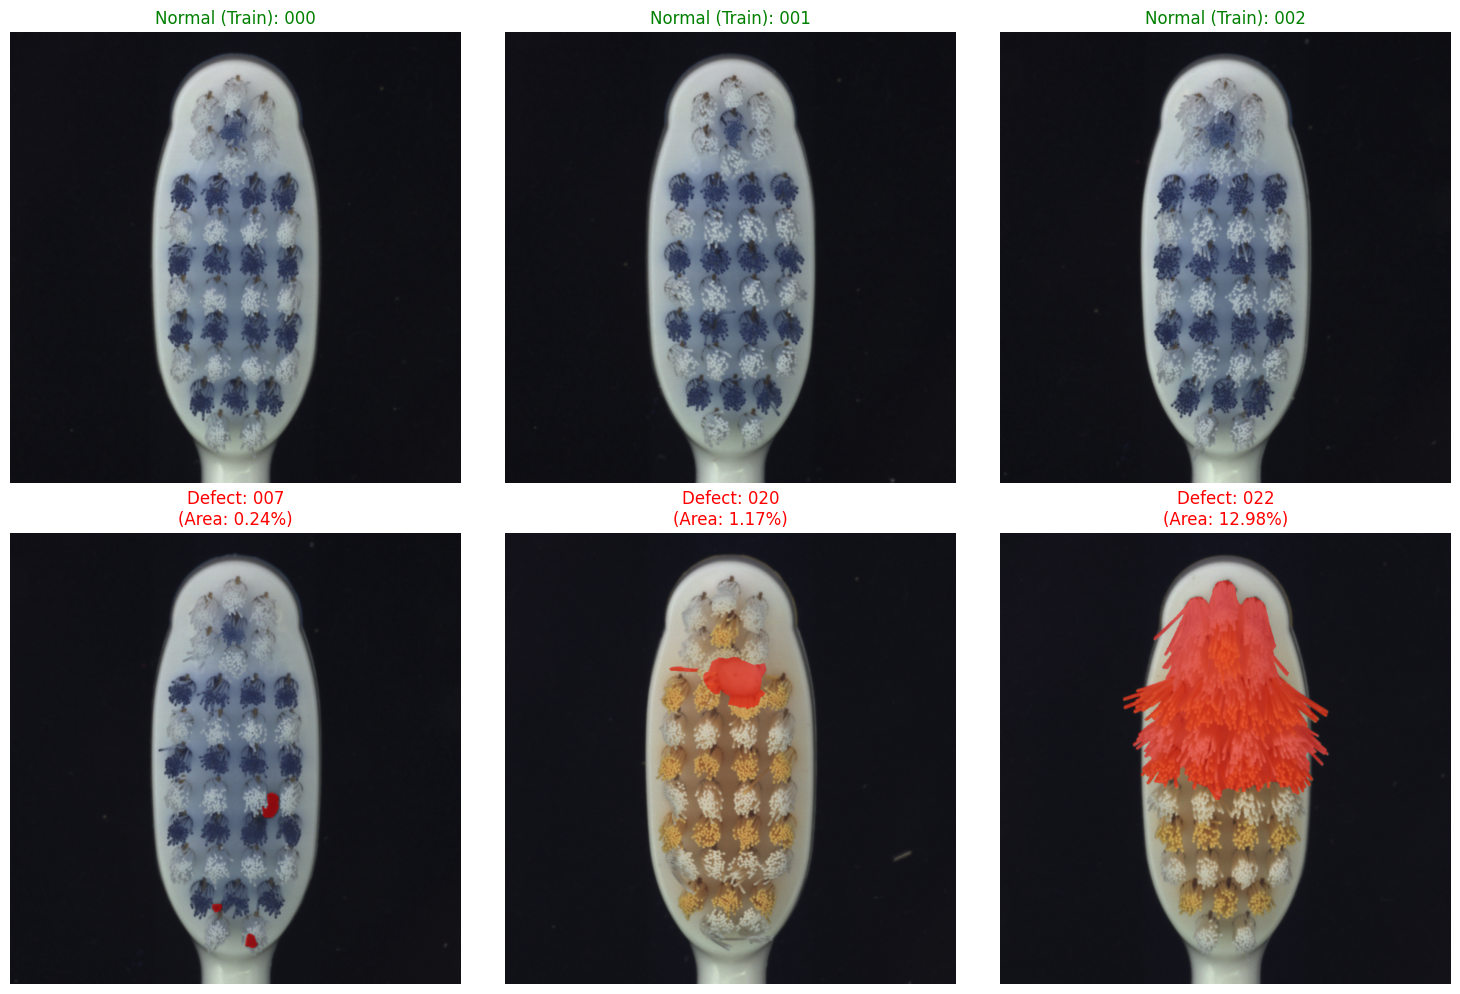

In [5]:
import matplotlib.pyplot as plt

def create_mask_overlay(image_pil, mask_pil, alpha=0.5):
    """Blends a binary mask onto an RGB image with a red highlight."""
    img_arr = np.array(image_pil).astype(float)
    mask_arr = np.array(mask_pil)
    
    # Red overlay: [R=255, G=0, B=0]
    red_color = np.array([255.0, 0.0, 0.0])
    
    # Find defect pixels
    defect_mask = (mask_arr == 255)
    
    # Blend red color over the defect region
    img_arr[defect_mask] = (1 - alpha) * img_arr[defect_mask] + alpha * red_color
    return img_arr.astype(np.uint8)

# Select 3 Normal images
sample_train_paths = train_good_paths[:3]

# Select 3 Defective images: smallest defect (007), a median defect, and largest defect
sorted_defects = df_defects.sort_values(by="defect_pixels")
smallest_id = sorted_defects.iloc[0]["image_id"]
median_id = sorted_defects.iloc[len(sorted_defects) // 2]["image_id"]
largest_id = sorted_defects.iloc[-1]["image_id"]

selected_defect_ids = [smallest_id, median_id, largest_id]
selected_defect_paths = [
    DATA_DIR / "test" / "defective" / f"{img_id}.png" for img_id in selected_defect_ids
]
selected_mask_paths = [
    DATA_DIR / "ground_truth" / "defective" / f"{img_id}_mask.png" for img_id in selected_defect_ids
]

# Plot side-by-side
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Plot Normals
for i, p in enumerate(sample_train_paths):
    with Image.open(p) as img:
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Normal (Train): {p.stem}", fontsize=12, color="green")
        axes[0, i].axis("off")

# Plot Defectives with Overlays
for i, (img_p, mask_p) in enumerate(zip(selected_defect_paths, selected_mask_paths)):
    with Image.open(img_p) as img, Image.open(mask_p) as mask:
        overlay = create_mask_overlay(img, mask, alpha=0.5)
        defect_area = df_defects[df_defects["image_id"] == img_p.stem]["defect_area_pct"].values[0]
        axes[1, i].imshow(overlay)
        axes[1, i].set_title(f"Defect: {img_p.stem}\n(Area: {defect_area:.2f}%)", fontsize=12, color="red")
        axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [7]:
### Summary of Toothbrush Data Audit (EDA)

1. **Dataset Composition:**
   - **Training Set:** 60 images (100% normal/good).
   - **Test Set:** 42 images (12 normal, 30 defective).
   - **Ground Truth:** 30 pixel-level binary masks with 100% verified 1-to-1 pairing.

2. **Image Properties:**
   - Native Resolution: 1024 x 1024 RGB (lossless PNG).
   - Mask Type: Strictly binary (0 for background, 255 for defect).

3. **Defect Spatial Distribution:**
   - Minimum Defect Area: 0.2381% (2,497 pixels at 1024x1024 -> ~156 pixels at 256x256).
   - Median Defect Area: 1.0778% (11,302 pixels).
   - Maximum Defect Area: 12.9764% (136,067 pixels).
   - **Resolution Conclusion:** Resizing to 256 x 256 is mathematically safe; even the smallest defect retains >150 pixels of spatial context.

4. **Visual & Fixturing Characteristics:**
   - Products are centered and vertically oriented with uniform dark backgrounds.
   - Defects are concentrated primarily on the brush head (bristle deformations, cut tufts, contamination).

SyntaxError: invalid decimal literal (1030863091.py, line 13)